Delta T/Pi
0.1
T
[0, 0.3141592653589793, 0.6283185307179586, 0.9424777960769379, 1.2566370614359172, 1.5707963267948966, 1.8849555921538759, 2.199114857512855, 2.5132741228718345, 2.827433388230814, 3.141592653589793, 3.4557519189487724, 3.7699111843077517, 4.084070449666731, 4.39822971502571, 4.71238898038469, 5.026548245743669, 5.340707511102648, 5.654866776461628, 5.969026041820607, 6.283185307179586, 6.5973445725385655, 6.911503837897545, 7.225663103256524, 7.5398223686155035, 7.853981633974483, 8.168140899333462, 8.482300164692441, 8.79645943005142, 9.1106186954104, 9.42477796076938, 9.738937226128359, 10.053096491487338, 10.367255756846317, 10.681415022205297, 10.995574287564276, 11.309733552923255, 11.623892818282235, 11.938052083641214, 12.252211349000193, 12.566370614359172, 12.880529879718152, 13.194689145077131, 13.50884841043611, 13.82300767579509, 14.137166941154069, 14.451326206513048, 14.765485471872028, 15.079644737231007, 15.393804002589986, 15.707963267948966, 16.0221

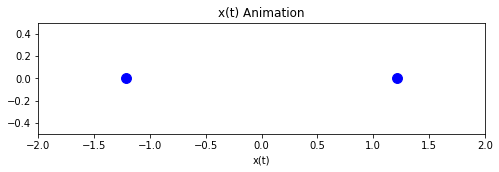

In [1]:
from mpl_toolkits.mplot3d.axes3d import axis3d
import math
import matplotlib.pyplot as plt
from matplotlib import rc
rc('animation',html='jshtml')
import numpy as np
from mpl_toolkits import mplot3d as plt3d
import matplotlib.animation as animation

fig=plt.figure(figsize=(8,2),dpi=72,clear=True)


pi=math.pi
time=[]
x_t=[]
v_t=[]
a_t=[]
x_t_exact=[]
error=[]
E=[]
def d(x,y):#returns derivative of a given point
  return y/x
def plotgraph(xarr,yarr,lx,ly):#     Takes two arrays and, using the first array's values as x coordinates 
                              #     and the second one's for y coordinates, plots them, and then proceeding 
  plt.plot(xarr,yarr)      #     to label the x axis as whatever 'lx' is and labels the y axis with the 'ly' argument
  plt.xlabel(lx)
  plt.ylabel(ly)
  return plt.plot
                       
  

def avg(var1, var2):
  var_sum=((var1+var2))
  return var_sum/2
def pr(formula):#So I don't have to write out the whole word every time... We programmers are kind of lazy I guess
  print(formula)
def pw(b,e):#Me being lazy again...
  return math.pow(b,e) 
def _2(base_number):
  return (base_number*base_number)
def abs(var):#absolute value function
  var2=_2(var)
  return math.sqrt(var2)

xt=1 #Original X value
vt=0 #Original velocity
at=-1 #Original acceleration
error1=0 #We start with no error
E1=.5 #Total energy
#@markdown Choose Which Equation:
equation="Verlet" #@param ["Verlet", "Euler"]
#@markdown Time step/pi:
deltat=0.1#@param {type:"number"}
#@markdown How many time steps you want it to display
Length_Of_Run = 200#@param {type:"number"}
#@markdown k, or the Spring Stiffness Constant
k= 1 #@param {type:"number"} 
#@markdown m, or the Mass of the object, in grams
m= 1#@param {type:"number"}
#@markdown Number of Animation frames shown per second in animation: *Note that the human eye will start to see motion somewhere between 30-60 fps
fps=60 #@param {type:"number"}  
intrvl=1000/fps#this takes desired fps and converts it to millisecond delay between frames
#@markdown How much delay before the animation repeats, in milliseconds
r_d=1000#@param {type:"number"}
#@markdown This changes how big the ball(which represents the object attached to spring) will be in the animation:   
ball_radius = 98 #@param {type:"slider", min:30, max:200, step:1}
#@markdown Color of ball shown in animation(r for red, g for green, b for blue)
ball_color= "b" #@param ["r","g","b"]
ballvar=ball_color+"o" #takes color and formats it into a marker style, by adding the o it makes a circle colored according to ball_color 
#@markdown Number of animation frames to run *Note: number of frames can't be more than Length of run
nframes=1000 #@param {type:"number"}
if nframes>Length_Of_Run:
  pr("Warning: number of animation frames cannot be larger than length of run. defaulting to length of run")
  nframes=Length_Of_Run 
x_t.append(xt) #Putting above values into respective arrays
v_t.append(vt)
a_t.append(at)
error.append(error1)
E.append(E1)


deltaT=deltat*pi
def  enmrte(times): #calculates and writes down the different formulas (Main function)
  t1=1 #Creating an index for each variable
  xt1=0
  vt1=0
  at1=0
  xte1=1
  er1=0
  e1=0
  time.append(0)
  x_t_exact.append(1)
  o=0#placeholder for equation output
  for i in range(times-1):
    if equation=="Verlet":
      o=t1*deltaT #T
      time.append(o)
      t1+=1
      
      
      o=math.cos(xte1*deltaT)# x(t) exact
      x_t_exact.append(o)        
      xte1+=1

      o=x_t[len(x_t)-1]+v_t[len(x_t)-1]*deltaT+.5*a_t[len(x_t)-1]*_2(deltaT) #x(t)
      x_t.append(o)
      xt1+=1
      
      o=(-1*k*x_t[len(x_t)-1])/m #a(t)
      a_t.append(o)
      at1+=1

      o=v_t[len(v_t)-1]+.5*(a_t[len(a_t)-2]+a_t[len(a_t)-1])*deltaT #v(t)
      v_t.append(o)
      vt1+=1
      
      o=.5*m*_2(v_t[len(v_t)-1])+.5*k*_2(x_t[len(x_t)-1]) #Energy
      E.append(o)
      e1+=1
    
      o=abs(abs(x_t_exact[len(x_t_exact)-1])-abs(x_t[len(x_t)-1]))#error
      
      error.append(o)
      er1+=1
    if equation=="Euler":
      o=t1*deltaT #T
      time.append(o)
      t1+=1
      
      
      o=math.cos(xte1*deltaT)# x(t) exact
      x_t_exact.append(o)        
      xte1+=1
      
      o=x_t[len(x_t)-1]+v_t[len(x_t)-1]*deltaT+.5*a_t[len(x_t)-1]*_2(deltaT) #x(t)
      x_t.append(o)
      xt1+=1
      
      o=(-1*k*x_t[len(x_t)-1])/m #a(t)
      a_t.append(o)
      at1+=1
      
      o=v_t[vt1]+a_t[at1-1]*deltaT#v(t)
      v_t.append(o)
      vt1+=1

      o=.5*m*_2(v_t[len(v_t)-1])+.5*k*_2(x_t[len(x_t)-1]) #Energy
      E.append(o)
      e1+=1

      o=abs(abs(x_t_exact[len(x_t_exact)-1])-abs(x_t[len(x_t)-1]))#error
      error.append(o)
      er1+=1
            
  pr("Delta T/Pi")    #this section prints arrays and their titles
  pr(deltat)
  pr("T")
  pr(time)
  pr("x(t)")
  pr(x_t)
  pr("v(t)")
  pr(v_t)
  pr("a(t)")
  pr(a_t)
  pr("x(t) exact")
  pr(x_t_exact)
  pr("error")
  pr(error)
p=0
ax=plt.axes()
enmrte(Length_Of_Run)#executes main  function
def frame(w):#for x(t)
  
  global p
  global ball_radius
  global ball_color
  if not p>=w:
    
    if p==0:#first frame
      
      global x1,x2,y,d
      d=x_t[p]+1.5
      x1=0-.5*d
      x2=0+.5*d
      x=[x1,x2]
      y=[0,0] #I fixed y, as they y does not change
    elif p%2==0:#any subsequent even frame index
      d=x_t[p]+1.5
      x1=0-.5*d
      x2=0+.5*d
      x=[x1,x2]
      y=[0,0]
    elif p%2==1:#any subsequent odd frame index
      d=x_t[p]+1.5
      x1=0-.5*d
      x2=0+.5*d
      y=[0,0]
      x=[x1,x2]
    ax.clear()    
    plt.title("x(t) Animation")
    ax.set_xlabel("x(t)")
    ax.set_xlim(-2.0,2.0)
    ax.set_ylim(-.5,.5)
    ax.scatter(x,y,s=ball_radius,c=ball_color)
    p+=1
anim = animation.FuncAnimation(fig, frame, frames=nframes, blit=False, repeat=True,repeat_delay=r_d,interval=intrvl)
anim

Text(0, 0.5, 'Total Energy')

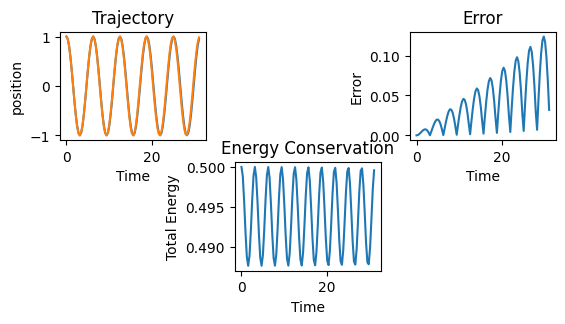

In [21]:
#plots information. For trajectory graph, x(t) exact is in blue, and x(t) in yellow 
fig=plt.figure()
plt.subplot(331)
plt.title("Trajectory")
plt.plot(time, x_t_exact)
plt.plot(time,x_t)
plt.xlabel("Time")
plt.ylabel("position")
plt.subplot(333)
plt.title("Error")
plt.plot(time,error)
plt.xlabel("Time")
plt.ylabel("Error")
plt.subplot(335)
plt.title("Energy Conservation")
plt.plot(time, E)
plt.xlabel("Time")
plt.ylabel("Total Energy")